In [46]:
from abacusnbody.data.read_abacus import read_asdf
import numpy as np
import matplotlib.pyplot as plt
#from abacusnbody.analysis.tpcf_corrfunc import calc_power
import os
from astropy.table import vstack
from pycorr.correlation_function import TwoPointCorrelationFunction

In [47]:
mapdir = "maps_072926/MapTune_bmerge_proper_0p01_Amerge_36p707/maplogs/col000"

#read in files
filelist = []
for root, dirs, files in os.walk(mapdir):
    for file in files:
        if "asdf" in file:
            filelist.append(root+"/"+file)

In [3]:
tables = [read_asdf(file,load='all') for file in filelist]
tab = vstack(tables)

#Position is returned in Mpc/h (5 kpc/h quantum, fixed); velocity in km/s

In [160]:
tab[tab['node_type'] == 0]

pos,vel,mult,control,node_type,timestep,mult_sec,pid,density,vel_disp,length,vel_rel,lc_label,x,y,z
float32[3],float32[3],int32,uint16,uint8,int32,int32,uint16[3],float32,float32,int32,float32,uint8,float32,float32,float32
-90.60156 .. -67.90625,-196.0 .. 164.0,21,1520,0,380,0,38456 .. 0,0.0,0.0,0,0.0,0,-90.60156,-99.22656,-67.90625
-89.60156 .. -68.578125,-216.0 .. 138.0,21,940,0,235,0,38706 .. 0,0.0,0.0,0,0.0,0,-89.60156,-97.47656,-68.578125
-89.78125 .. -68.22656,-246.0 .. 162.0,20,1368,0,342,0,9870 .. 0,0.0,0.0,0,0.0,0,-89.78125,-98.71094,-68.22656
-90.015625 .. -7.234375,-156.0 .. 114.0,21,1224,0,306,0,29616 .. 0,0.0,0.0,0,0.0,0,-90.015625,-100.82031,-7.234375
-92.32031 .. 37.773438,-40.0 .. -190.0,21,968,0,242,0,45359 .. 0,0.0,0.0,0,0.0,0,-92.32031,-99.91406,37.773438
-92.0625 .. 37.953125,-32.0 .. -196.0,21,1152,0,288,0,27771 .. 0,0.0,0.0,0,0.0,0,-92.0625,-99.83594,37.953125
-90.671875 .. 61.578125,-124.0 .. -26.0,21,960,0,240,0,2290 .. 0,0.0,0.0,0,0.0,0,-90.671875,-98.09375,61.578125
-91.24219 .. 80.75,-122.0 .. 62.0,20,1064,0,266,0,48783 .. 0,0.0,0.0,0,0.0,0,-91.24219,-96.85156,80.75
-92.015625 .. 90.46094,-256.0 .. -300.0,20,2136,0,534,0,27305 .. 0,0.0,0.0,0,0.0,0,-92.015625,-100.83594,90.46094


In [107]:
tab['pid'][:,2]

0
0
0
0
0
0
0
0
0
0
0


In [5]:
#Just get a handle on what we're looking at
tab['x'] = tab['pos'][:,0]
tab['y'] = tab['pos'][:,1]
tab['z'] = tab['pos'][:,2]

In [142]:
#let's select all the maps at redshift 0.2 (I think?), timestep 665
#we need node_type 3
#we will then plot a correlation function by metallicity
z_0p2_mask = (tab['node_type'] == 3)&(tab['timestep']==665)
maps_z0_2 = tab[z_0p2_mask]
print(len(maps_z0_2))

761563


In [24]:
highmult = maps_z0_2[maps_z0_2['mult'] > 150]

Text(0, 0.5, 'Number of MAPs')

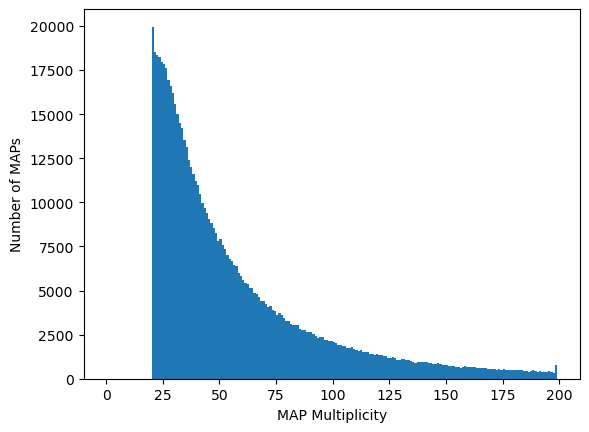

In [7]:
plt.hist(maps_z0_2['mult'],bins=np.arange(0,200))
plt.xlabel("MAP Multiplicity")
plt.ylabel("Number of MAPs")

In [19]:
#calculate the correlation function

sbins = np.logspace(-2,2,num=20)
cart_pos = np.array([maps_z0_2['x'],maps_z0_2['y'],maps_z0_2['z']])
tpcf_all = TwoPointCorrelationFunction("s",sbins,cart_pos,boxsize=2*102.5)
tpcf_all.save("correlationfunction/tpcf_all")

In [25]:
cart_pos = np.array([highmult['x'],highmult['y'],highmult['z']])
tpcf_highmult = TwoPointCorrelationFunction("s",sbins,cart_pos,boxsize=2*102.5)
tpcf_highmult.save("correlationfunction/tpcf_highmult")

In [42]:
mult_70 = maps_z0_2[maps_z0_2['mult'] > 70]
cart_pos = np.array([mult_70['x'],mult_70['y'],mult_70['z']])
tpcf_70 = TwoPointCorrelationFunction("s",sbins,cart_pos,boxsize=2*102.5)
tpcf_70.save("correlationfunction/tpcf_mult70")

In [36]:
binsmed = (sbins[:-1]+ sbins[1:])/2

In [43]:
allcorr = tpcf_all.get_corr()*binsmed**2
highmultcorr = tpcf_highmult.get_corr()*binsmed**2
corr70 = tpcf_70.get_corr()*binsmed**2

Text(0.5, 1.0, 'MAP Clustering for Several Multiplicities')

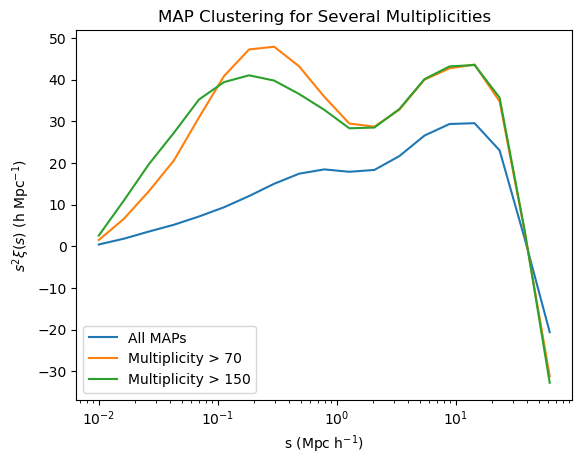

In [44]:
plt.figure()
plt.plot(sbins[:-1],allcorr,label='All MAPs')
plt.plot(sbins[:-1],corr70,label='Multiplicity > 70')
plt.plot(sbins[:-1],highmultcorr,label='Multiplicity > 150')
plt.legend()
plt.xlabel(r"s (Mpc h$^{-1}$)")
plt.xscale('log')
plt.ylabel(r"$s^2\xi(s)$ (h Mpc$^{-1}$)")
plt.title("MAP Clustering for Several Multiplicities")


In [ ]:
def get_parents(maplogtab,timestep):
    parent_mask = (maplogtab['node_type'] == 3)&(maplogtab['timestep']==timestep)
    parent_indices = np.where(parent_mask)[0]
    return parent_mask, parent_indices

def get_nmergers(maplogtab,parent_indices):
    '''
    Description
        find all the MAPs at a certain timestep and then find the total number of mergers they went through
    Arguments
        maplogtab: Astropy tree of MAPs
        timestep: timestep where you want to find parent MAPs
    Returns:
        List of number of mergers each parent MAP has gone through'''
    #first get a list of all the indices of the parent MAPs you want

    def get_nmerger(index):
        #get length of the branch
        #check which steps in that branch are mergers
        length = maplogtab['length'][index] #get length of this branch
        onetree_nodetype = maplogtab['node_type'][index:index+length] #get node type of everything in branch
        mask = onetree_nodetype == 1 #only choose the merger nodes


        #check if onetree_nodetype[-1] is always formation
        nmergers = np.count_nonzero(mask)
        return nmergers
    
    nmerger_list = [get_nmerger(parent_indices[i]) for i in range(len(parent_indices))]
    return nmerger_list, parent_mask


def largestMergerSize(maplogtab,parent_indices):
    '''
    Description
            takes in a list of head nodes and finds the largest merger for to the main branch for each
    Arguments
        maplogtab: Astropy table of MAPs
        parent_indices: indices of head nodes you're interested in (for example, all the MAPs at a certain timestep)
    Returns
        size of the largest merger to the main branch as a fraction of main branch multiplicity
    '''

    def get_largestmerger(index):
        #get length of the branch
        #check which steps in that branch are mergers
        length = maplogtab['length'][index] #get length of this branch
        onetree_nodetype = maplogtab['node_type'][index:index+length] #get node type of everything in branch
        onetree_mult = maplogtab['mult_sec'][index:index+length]
        mask = onetree_nodetype == 1 #only choose the merger nodes
        if not np.any(mask): return 0
        else:
            largestmerger_ix = np.argmax(onetree_mult[mask])
            largestmerger_mult = onetree_mult[largestmerger_ix]
            return float(largestmerger_mult)/float(maplogtab['mult'][index])
        
    largestmerger_list = [get_largestmerger(parent_indices[i]) for i in range(len(parent_indices))]
    return np.array(largestmerger_list)

def getcorr(catalog,mask):



In [173]:
parent_indices = np.where(z_0p2_mask)[0]
largestmerger_z0p2 = largestMergerSize(tab,parent_indices)

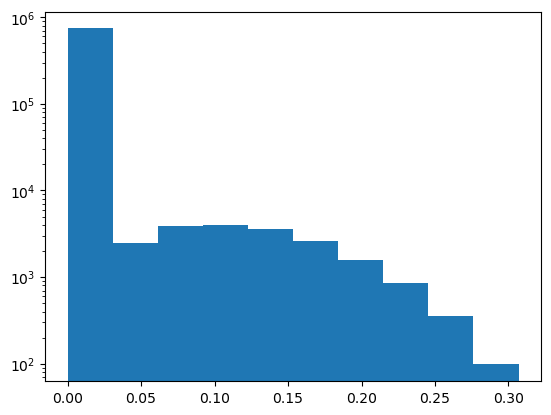

In [166]:
plt.hist(largestmerger_z0p2)
plt.yscale('log')

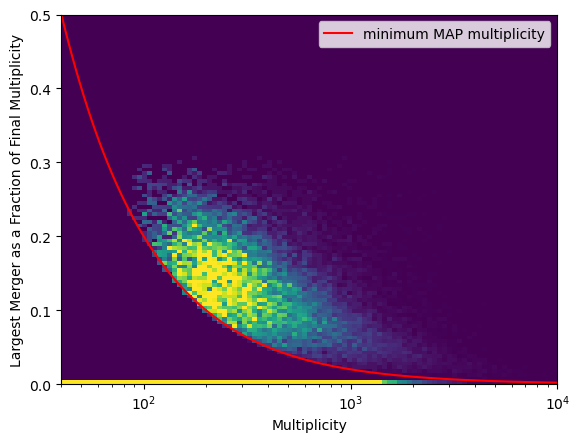

In [240]:
plt.hist2d(maps_z0_2['mult'],largestmerger_z0p2,bins=(np.logspace(np.log10(40),4,num=100),np.linspace(0,0.5,num=100)),density=True,vmax=7e-4)
plt.xlabel("Multiplicity")
plt.ylabel("Largest Merger as a Fraction of Final Multiplicity")
plt.xscale('log')

mults = np.logspace(0,4,num=200)
plt.plot(mults,20/mults,label='minimum MAP multiplicity',color='red')
plt.legend()
#plt.yscale('log')

Text(0.5, 1.0, 'MAP Mergers for Several Final Multiplicities')

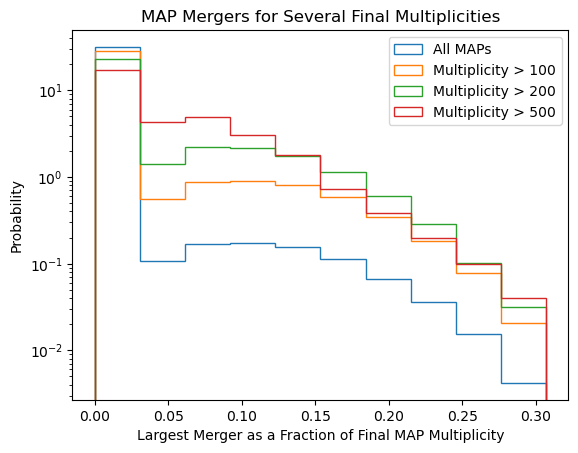

In [179]:
mask_200 = maps_z0_2['mult'] > 200
mask_100 = maps_z0_2['mult'] > 100
mask_500 = maps_z0_2['mult'] > 500

plt.hist(largestmerger_z0p2,label="All MAPs",histtype='step',density=True)
plt.hist(largestmerger_z0p2[mask_100],label = "Multiplicity > 100",density=True,histtype='step')
plt.hist(largestmerger_z0p2[mask_200],label = "Multiplicity > 200",density=True,histtype='step')
plt.hist(largestmerger_z0p2[mask_500],label = "Multiplicity > 500",density=True,histtype='step')
plt.legend()
plt.xlabel("Largest Merger as a Fraction of Final MAP Multiplicity")
plt.ylabel("Probability")
plt.yscale('log')

plt.title("MAP Mergers for Several Final Multiplicities")

In [201]:
bigmerg_0p1 = maps_z0_2[(largestmerger_z0p2 > 0.1)&(maps_z0_2['mult'] > 100)]
cart_pos = np.array([bigmerg_0p1['x'],bigmerg_0p1['y'],bigmerg_0p1['z']])
tpcf_bigmerg_0p1 = TwoPointCorrelationFunction("s",sbins,cart_pos,boxsize=2*102.5)
tpcf_bigmerg_0p1.save("correlationfunction/tpcf_bigmerg_0p1")

bigmerg_0p2 = maps_z0_2[(largestmerger_z0p2 > 0.2)&(maps_z0_2['mult'] > 100)]
cart_pos = np.array([bigmerg_0p2['x'],bigmerg_0p2['y'],bigmerg_0p2['z']])
tpcf_bigmerg_0p2 = TwoPointCorrelationFunction("s",sbins,cart_pos,boxsize=2*102.5)
tpcf_bigmerg_0p2.save("correlationfunction/tpcf_bigmerg_0p2")

all_multlim = maps_z0_2[(maps_z0_2['mult'] > 100)]
cart_pos = np.array([all_multlim['x'],all_multlim['y'],all_multlim['z']])
tpcf_all_multlim = TwoPointCorrelationFunction("s",sbins,cart_pos,boxsize=2*102.5)
tpcf_all_multlim.save("correlationfunction/tpcf_all_multlim")

In [202]:
corr_all_multlim = tpcf_all_multlim.get_corr()*binsmed**2
corr_bigmerg_0p2 = tpcf_bigmerg_0p2.get_corr()*binsmed**2
corr_bigmerg_0p1 = tpcf_bigmerg_0p1.get_corr()*binsmed**2

Text(0.5, 1.0, 'MAP Clustering for Different Merger Histories \n (MAP Multiplicity > 100)')

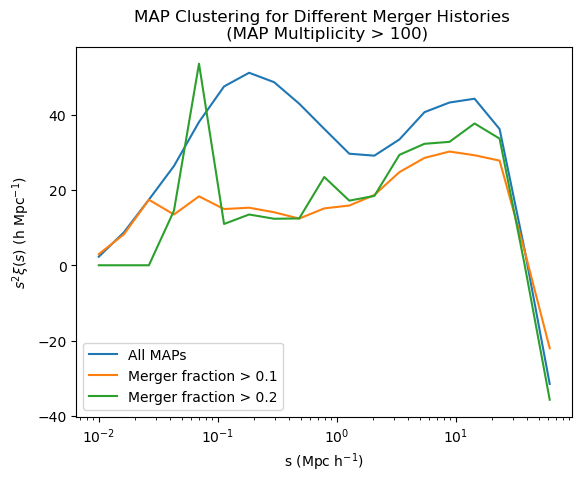

In [203]:
plt.figure()
plt.plot(sbins[:-1],corr_all_multlim,label='All MAPs')
plt.plot(sbins[:-1],corr_bigmerg_0p1,label='Merger fraction > 0.1')
plt.plot(sbins[:-1],corr_bigmerg_0p2,label='Merger fraction > 0.2')
plt.legend()
plt.xlabel(r"s (Mpc h$^{-1}$)")
plt.xscale('log')
plt.ylabel(r"$s^2\xi(s)$ (h Mpc$^{-1}$)")
plt.title("MAP Clustering for Different Merger Histories \n (MAP Multiplicity > 100)")

Text(0, 0.5, 'MAPs')

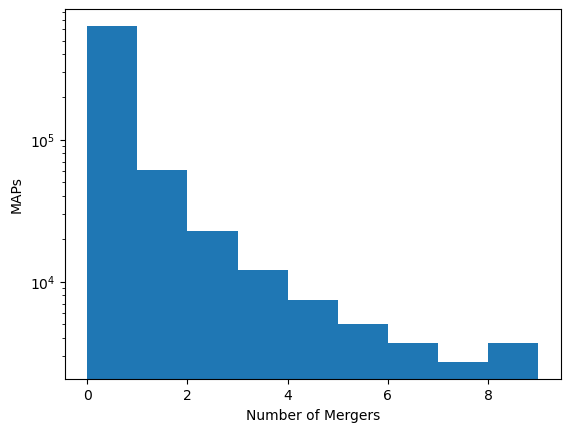

In [113]:
plt.hist(nmergers_z0_2,bins=np.arange(10))
plt.yscale('log')
plt.xlabel("Number of Mergers")
plt.ylabel("MAPs")

'plt.yscale("log")\nplt.xscale("log")'

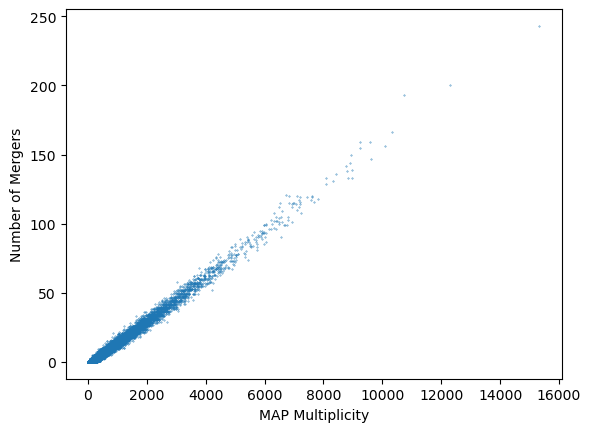

In [122]:
plt.scatter(maps_z0_2['mult'],nmergers_z0_2,s=0.1)
plt.xlabel("MAP Multiplicity")
plt.ylabel("Number of Mergers")
'''plt.yscale("log")
plt.xscale("log")'''

In [115]:
disrupted = maps_z0_2[np.array(nmergers_z0_2) > 1]

In [116]:
cart_pos = np.array([disrupted['x'],disrupted['y'],disrupted['z']])
tpcf_disrupted = TwoPointCorrelationFunction("s",sbins,cart_pos,boxsize=2*102.5)
tpcf_disrupted.save("correlationfunction/tpcf_disrupted")

In [117]:
disrupted_0 = maps_z0_2[np.array(nmergers_z0_2) > 0]
cart_pos = np.array([disrupted_0['x'],disrupted_0['y'],disrupted_0['z']])
tpcf_disrupted0 = TwoPointCorrelationFunction("s",sbins,cart_pos,boxsize=2*102.5)
tpcf_disrupted0.save("correlationfunction/tpcf_disrupted0")

In [118]:
disrupted_3 = maps_z0_2[np.array(nmergers_z0_2) > 3]
cart_pos = np.array([disrupted_3['x'],disrupted_3['y'],disrupted_3['z']])
tpcf_disrupted3 = TwoPointCorrelationFunction("s",sbins,cart_pos,boxsize=2*102.5)
tpcf_disrupted3.save("correlationfunction/tpcf_disrupted3")

In [119]:
disrupted_5 = maps_z0_2[np.array(nmergers_z0_2) > 5]
cart_pos = np.array([disrupted_5['x'],disrupted_5['y'],disrupted_5['z']])
tpcf_disrupted5 = TwoPointCorrelationFunction("s",sbins,cart_pos,boxsize=2*102.5)
tpcf_disrupted5.save("correlationfunction/tpcf_disrupted5")

In [120]:
corrdisrupted = tpcf_disrupted.get_corr()*binsmed**2
corrdisrupted0 = tpcf_disrupted0.get_corr()*binsmed**2
corrdisrupted3 = tpcf_disrupted3.get_corr()*binsmed**2
corrdisrupted5 = tpcf_disrupted5.get_corr()*binsmed**2

Text(0.5, 1.0, 'MAP Clustering for Different Merger Histories')

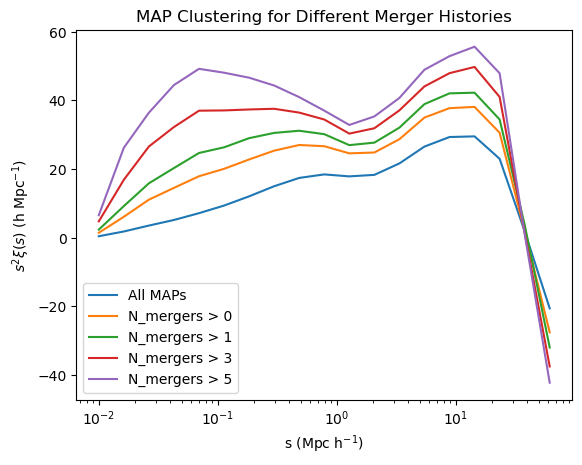

In [121]:
plt.figure()
plt.plot(sbins[:-1],allcorr,label='All MAPs')
plt.plot(sbins[:-1],corrdisrupted0,label='N_mergers > 0')
plt.plot(sbins[:-1],corrdisrupted,label='N_mergers > 1')
plt.plot(sbins[:-1],corrdisrupted3,label='N_mergers > 3')
plt.plot(sbins[:-1],corrdisrupted5,label='N_mergers > 5')
plt.legend()
plt.xlabel(r"s (Mpc h$^{-1}$)")
plt.xscale('log')
plt.ylabel(r"$s^2\xi(s)$ (h Mpc$^{-1}$)")
plt.title("MAP Clustering for Different Merger Histories")

Text(0.5, 1.0, 'MAP Multiplicity for Different Merger Histories')

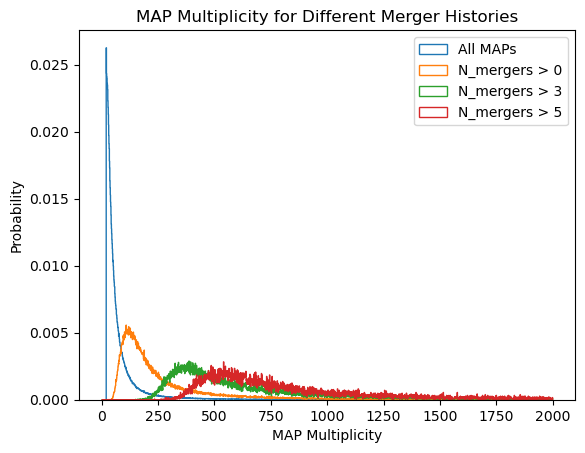

In [124]:
plt.hist(maps_z0_2['mult'],bins=np.arange(0,2000),density=True,label="All MAPs",histtype='step')
plt.hist(disrupted_0['mult'],bins=np.arange(0,2000),density=True,histtype='step',label = "N_mergers > 0")
#plt.hist(disrupted['mult'],bins=np.arange(0,200),density=True,histtype='step',label = "N_mergers > 1")
plt.hist(disrupted_3['mult'],bins=np.arange(0,2000),density=True,histtype='step',label = "N_mergers > 3")
plt.hist(disrupted_5['mult'],bins=np.arange(0,2000),density=True,histtype='step',label = "N_mergers > 5")
plt.legend()
plt.xlabel("MAP Multiplicity")
plt.ylabel("Probability")
plt.title("MAP Multiplicity for Different Merger Histories")

In [125]:
maps_z0_2['nmerg/mult'] = nmergers_z0_2/maps_z0_2['mult']

Text(0, 0.5, 'Number of MAPs')

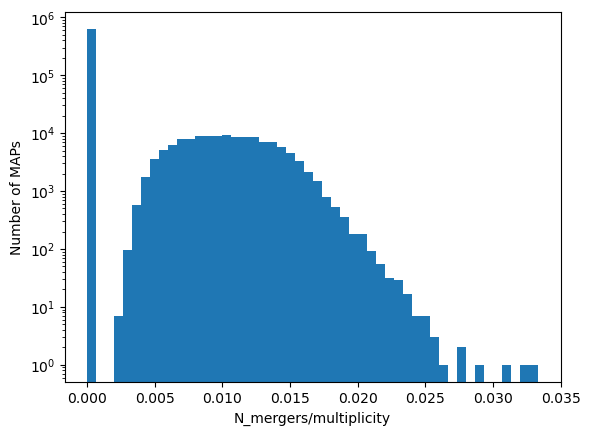

In [138]:
plt.hist(maps_z0_2['nmerg/mult'],bins=50)
plt.yscale('log')
plt.xlabel("N_mergers/multiplicity")
plt.ylabel("Number of MAPs")

In [129]:
mergmult_0p01 = maps_z0_2[maps_z0_2['nmerg/mult'] > 0.01]
cart_pos = np.array([mergmult_0p01['x'],mergmult_0p01['y'],mergmult_0p01['z']])
tpcf_mergmult_0p01 = TwoPointCorrelationFunction("s",sbins,cart_pos,boxsize=2*102.5)
tpcf_mergmult_0p01.save("correlationfunction/tpcf_mergmult_0p01")

In [134]:
mergmult_0p015 = maps_z0_2[maps_z0_2['nmerg/mult'] > 0.015]
cart_pos = np.array([mergmult_0p015['x'],mergmult_0p015['y'],mergmult_0p015['z']])
tpcf_mergmult_0p015 = TwoPointCorrelationFunction("s",sbins,cart_pos,boxsize=2*102.5)
tpcf_mergmult_0p015.save("correlationfunction/tpcf_mergmult_0p015")

In [136]:
corrmergmult_0p015 = tpcf_mergmult_0p015.get_corr()*binsmed**2
corrmergmult_0p01 = tpcf_mergmult_0p01.get_corr()*binsmed**2

Text(0.5, 1.0, 'MAP Clustering for Different Merger Histories')

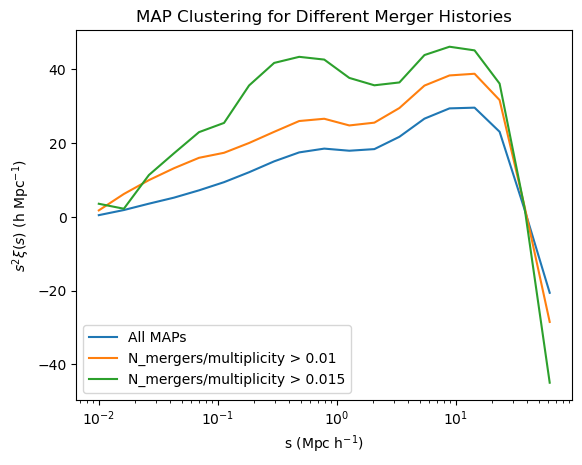

In [137]:
plt.figure()
plt.plot(sbins[:-1],allcorr,label='All MAPs')
plt.plot(sbins[:-1],corrmergmult_0p01,label='N_mergers/multiplicity > 0.01')
plt.plot(sbins[:-1],corrmergmult_0p015,label='N_mergers/multiplicity > 0.015')
plt.legend()
plt.xlabel(r"s (Mpc h$^{-1}$)")
plt.xscale('log')
plt.ylabel(r"$s^2\xi(s)$ (h Mpc$^{-1}$)")
plt.title("MAP Clustering for Different Merger Histories")